# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


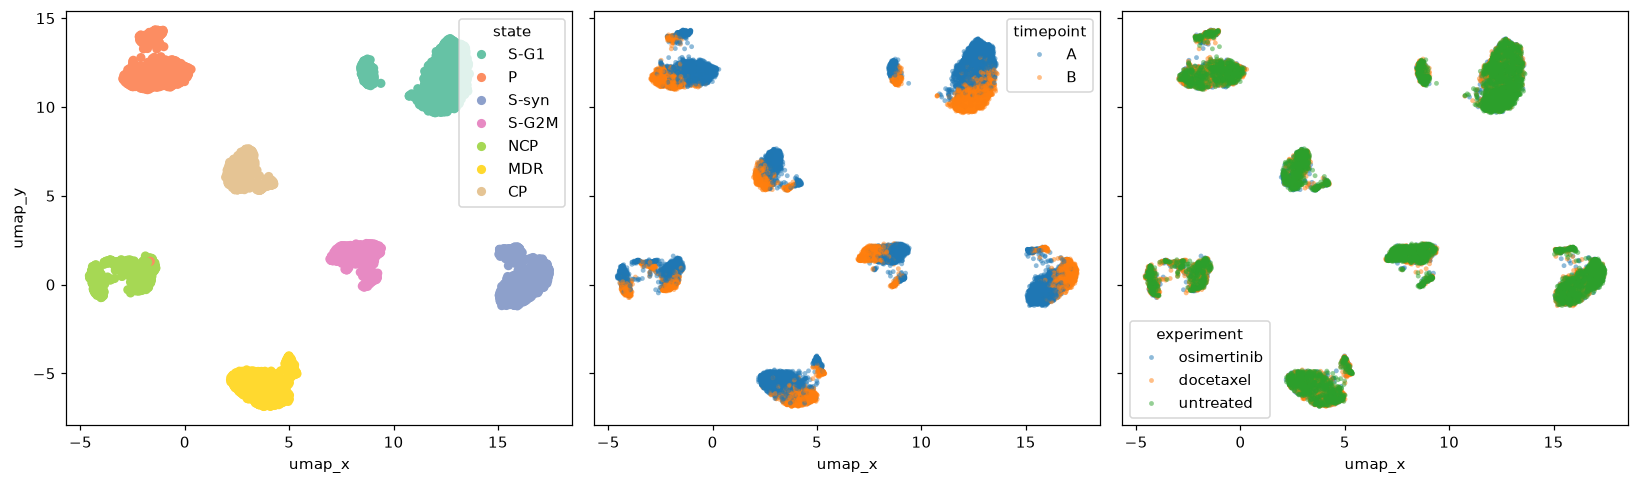

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."

In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
P_hat

state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121172,0.022636,0.014647,0.205060,0.054594,0.0,0.00000,0.581891
S-syn,0.059471,0.050661,0.037445,0.083700,0.035242,0.0,0.00000,0.733480
S-G2M,0.028571,0.046429,0.071429,0.071429,0.000000,0.0,0.00000,0.782143
P,0.103297,0.024176,0.017582,0.351648,0.164835,0.0,0.00000,0.338462
NCP,0.060897,0.000000,0.000000,0.099359,0.490385,0.0,0.00000,0.349359
CP,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.00000,0.000000
MDR,0.042644,0.029851,0.021322,0.029851,0.000000,0.0,0.17484,0.701493
cleared,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,1.000000


In [11]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

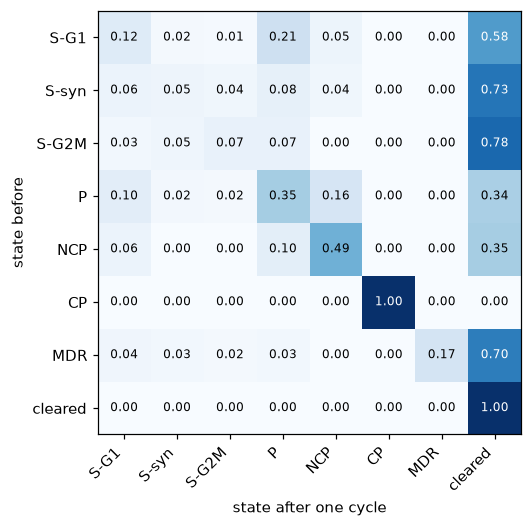

In [12]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

<div class='alert alert-success'>
<b>Answer:</b> 

- An absorbing state is a state from which the cells cannot escape.
- Other than cleared, CP cells (GSTM3 gene) shows similar behaviour.
- If a cell reaches CP state, it cannot transition into anything else and the probability of staying in the state is 1.
- In terms of drug treatment, it means that if a cell reaches CP state, it will stay there and wont transit into any other state.
- Hence it wont ever move to cleared state and hence it becomes impossible to eliminate it under osimertinib drug treatment.
</div>

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [13]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [14]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [15]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

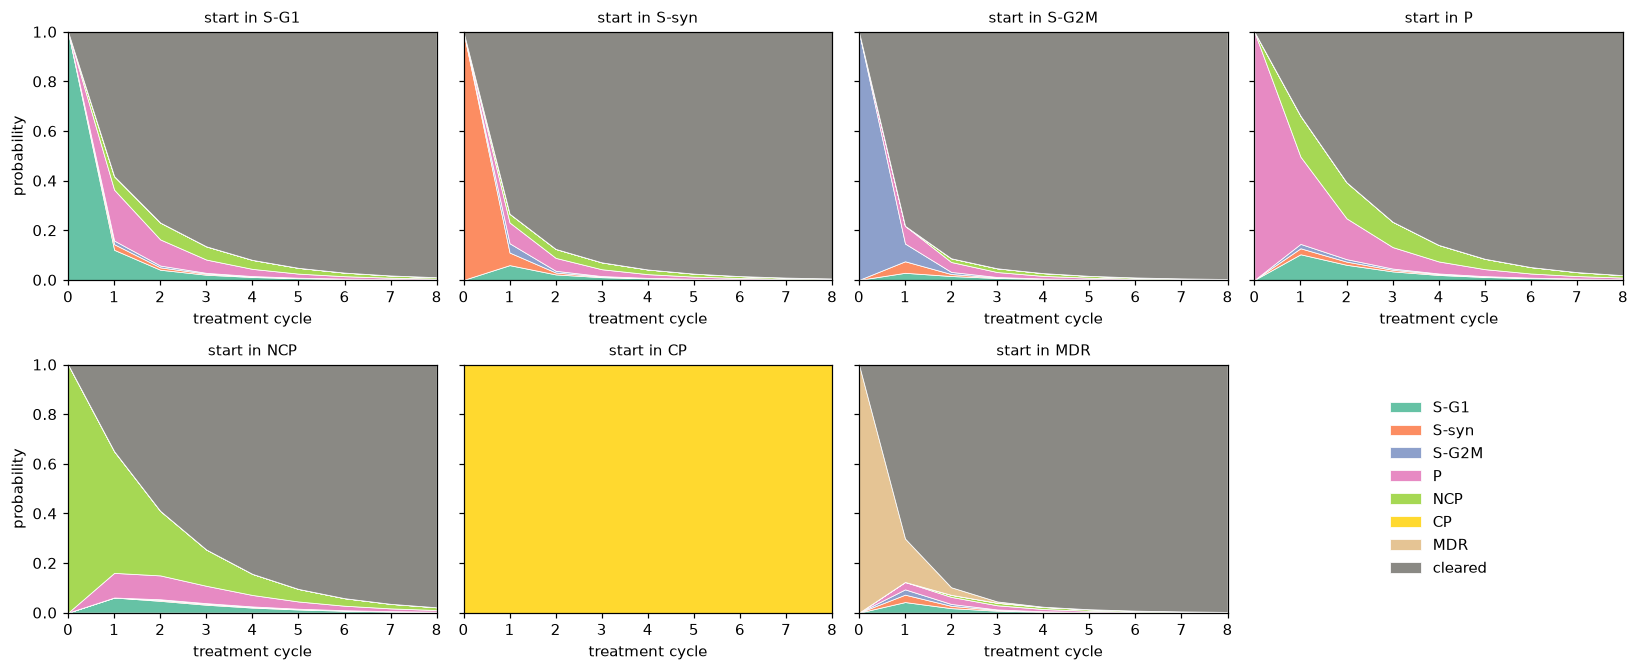

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [16]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

In [17]:
alive8 = {s: 1 - evolve(basis(s, P_hat), P_hat, 8)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 8 cycles, starting in", s, ":", round(v, 3))

fraction alive after 8 cycles, starting in S-G1 : 0.081
fraction alive after 8 cycles, starting in S-syn : 0.042
fraction alive after 8 cycles, starting in S-G2M : 0.027
fraction alive after 8 cycles, starting in P : 0.141
fraction alive after 8 cycles, starting in NCP : 0.156
fraction alive after 8 cycles, starting in CP : 1.0
fraction alive after 8 cycles, starting in MDR : 0.024
fraction alive after 8 cycles, starting in cleared : 0.0


In [18]:
alive10 = {s: 1 - evolve(basis(s, P_hat), P_hat, 10)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 10 cycles, starting in", s, ":", round(v, 4))

fraction alive after 10 cycles, starting in S-G1 : 0.0806
fraction alive after 10 cycles, starting in S-syn : 0.0419
fraction alive after 10 cycles, starting in S-G2M : 0.0272
fraction alive after 10 cycles, starting in P : 0.1408
fraction alive after 10 cycles, starting in NCP : 0.1562
fraction alive after 10 cycles, starting in CP : 1.0
fraction alive after 10 cycles, starting in MDR : 0.0237
fraction alive after 10 cycles, starting in cleared : 0.0


In [19]:
alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 15)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 15 cycles, starting in", s, ":", round(v, 4))

fraction alive after 15 cycles, starting in S-G1 : 0.0003
fraction alive after 15 cycles, starting in S-syn : 0.0002
fraction alive after 15 cycles, starting in S-G2M : 0.0001
fraction alive after 15 cycles, starting in P : 0.0006
fraction alive after 15 cycles, starting in NCP : 0.0007
fraction alive after 15 cycles, starting in CP : 1.0
fraction alive after 15 cycles, starting in MDR : 0.0001
fraction alive after 15 cycles, starting in cleared : 0.0


In [20]:
alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 3)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 3 cycles, starting in", s, ":", round(v, 3))

fraction alive after 3 cycles, starting in S-G1 : 0.135
fraction alive after 3 cycles, starting in S-syn : 0.071
fraction alive after 3 cycles, starting in S-G2M : 0.047
fraction alive after 3 cycles, starting in P : 0.234
fraction alive after 3 cycles, starting in NCP : 0.254
fraction alive after 3 cycles, starting in CP : 1.0
fraction alive after 3 cycles, starting in MDR : 0.045
fraction alive after 3 cycles, starting in cleared : 0.0


<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>

<div class='alert alert-success'>

- All starting states except CP (SG1, Ssyn, SG2M, P, NCP, MDR) end up almost equal to zero after a certain number of cycles.
- CP state stays in the same state showing zero effect from the osimertinib drug.
- Of the clear states, as evident from the plots, NCP lasts the longest. From the transition matrix, its probability to stay in the same state is higher than getting cleared. Hence, it takes a longer time.
- The state CP is almost equal to an absorbing state, the drug has no effect on it. So it stays the same for 8, 10 or 15 cycles.
- The state CP isnt changing so it has the highest proportion after 3 cycles. Following CP, is NCP with 0.254 population alive.
</div>

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [21]:
A = cells[cells.timepoint == "A"]
pi_mix = A.state.value_counts(normalize=True).reindex(OUTCOMES, fill_value=0).to_numpy()  # Adding 0 for cleared state which is zero for state A

traj = evolve(pi_mix, P_hat, 10)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893
9,0.001,0.000,0.000,0.002,0.003,0.097,0.000,0.897


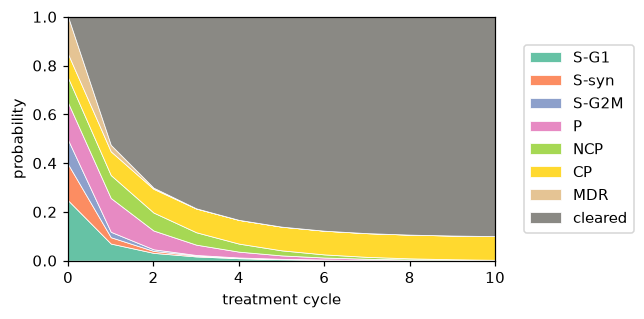

In [22]:
t = np.arange(len(traj))

fig, ax = plt.subplots(figsize=(6,3))
ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
             edgecolor="white", linewidth=0.5)
ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
ax.set_xlabel("treatment cycle")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1.05, 0.5))
plt.tight_layout()
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

<div class = "alert alert-success"> 

- After 10 cycles, most of the states end up in the cleared state. Only the cells in CP stay exactly the same as they were initially.
- Reason for this is the column and row for cp, except cp is zero. Hence no states transform to cp, and cp doesnt transform to any state.
- Hence, after few more cycles all except CP will be in cleared. At the end the proportion will be 0.903 cleared and 0.097 CP.
- From the transition matrix, if the diagonal value for any state is 1, it means that the proportion of that state will stay the same at the endpoint.
- Here, CP and Cleared have 1, which shows once the cells reach there, they cannot escape the state and stay there till the end.
</div>

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [23]:
# Defining function to make a transition matrix
def transition_matrix(drug):
    drg = cells[cells["experiment"] == drug]
    at_A = drg[drg.timepoint == "A"][["lineage_tag", "state"]]
    at_B = drg[drg.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")
    
    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))

    P_hat = counts.div(counts.sum(axis=1), axis=0)

    P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

    return P_hat

# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()

P_doc = transition_matrix('docetaxel')     # TODO

P_holiday = transition_matrix('untreated')   # TODO

### Simulation with Docetaxel

In [24]:
P_doc

state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.293478,0.101902,0.020380,0.091033,0.081522,0.0,0.035326,0.376359
S-syn,0.050000,0.111364,0.136364,0.050000,0.031818,0.0,0.000000,0.620455
S-G2M,0.028169,0.024648,0.035211,0.021127,0.021127,0.0,0.000000,0.869718
P,0.090147,0.039832,0.020964,0.408805,0.073375,0.0,0.014675,0.352201
NCP,0.075235,0.000000,0.003135,0.094044,0.435737,0.0,0.021944,0.369906
CP,0.079310,0.034483,0.034483,0.027586,0.000000,0.1,0.000000,0.724138
MDR,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.000000,0.000000
cleared,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,1.000000


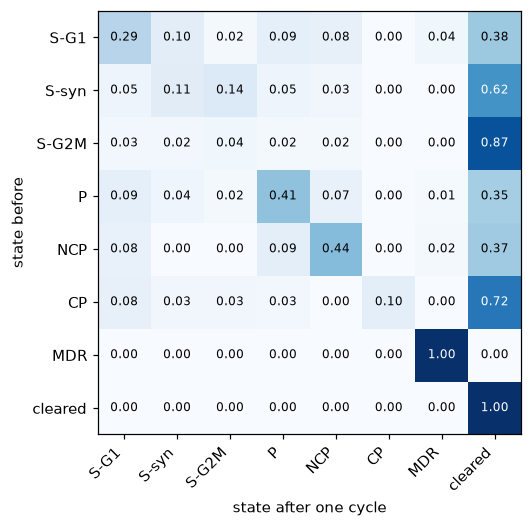

In [25]:
show_matrix(P_doc)

In [26]:
traj = evolve(pi_mix, P_doc, 10)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810
9,0.001,0.000,0.000,0.001,0.001,0.000,0.183,0.813


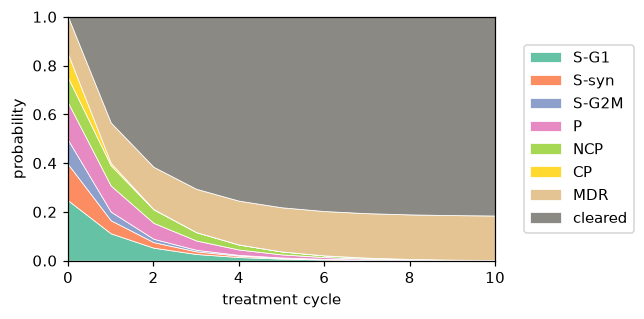

In [27]:
t = np.arange(len(traj))

fig, ax = plt.subplots(figsize=(6,3))
ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
             edgecolor="white", linewidth=0.5)
ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
ax.set_xlabel("treatment cycle")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1.05, 0.5))
plt.tight_layout()
plt.show()

In [28]:
P_doc = P_doc.to_numpy()

### Simulation with drug holiday (untreated)

In [29]:
P_holiday

state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.411685,0.430707,0.107337,0.000000,0.000000,0.000000,0.000000,0.050272
S-syn,0.092971,0.342404,0.517007,0.000000,0.000000,0.000000,0.000000,0.047619
S-G2M,0.570997,0.099698,0.268882,0.000000,0.000000,0.000000,0.000000,0.060423
P,0.412698,0.099773,0.054422,0.324263,0.045351,0.000000,0.002268,0.061224
NCP,0.185567,0.068729,0.000000,0.226804,0.477663,0.000000,0.000000,0.041237
CP,0.058824,0.032680,0.035948,0.000000,0.000000,0.820261,0.000000,0.052288
MDR,0.319383,0.044053,0.044053,0.000000,0.000000,0.000000,0.541850,0.050661
cleared,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000


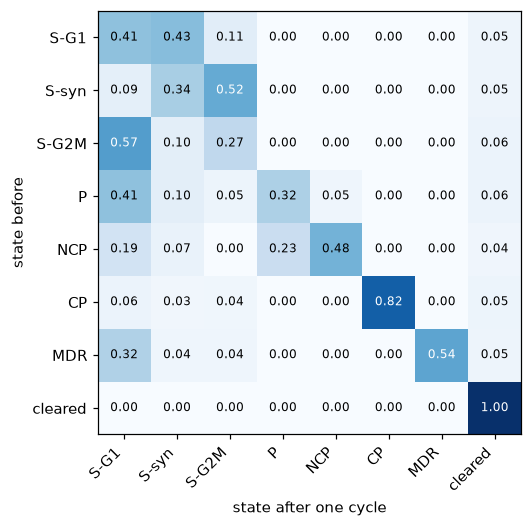

In [30]:
show_matrix(P_holiday)

In [31]:
traj = evolve(pi_mix, P_holiday, 10)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.309,0.199,0.148,0.073,0.056,0.080,0.083,0.052
2,0.302,0.233,0.187,0.036,0.030,0.065,0.045,0.101
3,0.291,0.238,0.210,0.019,0.016,0.054,0.025,0.148
4,0.283,0.234,0.215,0.010,0.008,0.044,0.013,0.192
5,0.274,0.227,0.212,0.005,0.004,0.036,0.007,0.235
6,0.262,0.219,0.206,0.003,0.002,0.030,0.004,0.275
7,0.250,0.210,0.198,0.001,0.001,0.024,0.002,0.313
8,0.239,0.201,0.190,0.001,0.001,0.020,0.001,0.349
9,0.227,0.191,0.181,0.000,0.000,0.016,0.001,0.383


In [32]:
P_holiday = P_holiday.to_numpy()

<div class='alert alert-success'>
<b>Answer:</b> 

- Under osimertinib treatment, SG1, Ssyn, and SG2M have a very high clearing probability. So the cells are killed before transition. For Docetaxel, SG1 and Ssyn clearing probability is low, so under docetaxel these cells live longer, transition into SG2M, but eventually get killed.
- Under osimertinib, CP was an absorbing state, so the cells in CP had no effect from the drug, and stayed the same. With docetaxel, CP can be transitioned into cleared and as seen in the simulation, it gets all transitioned to cleared state.
- With docetaxel, the state MDR becomes absorbing. states like P and NCP transition into MDR, but once the cells reach MDR state they stay there with no harm from the drug. As seen in the simulation, the proportion increases in initial cycles and then becomes constant.
- Under drug holiday, the recovery/clearing rate is very low. But there are no absorbing states under holiday, hence it can be beneficial and used to reduce the cells reached absorbing states like MDR and CP after some cycles of osimertinib or docetaxel.
</div>

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [33]:
P_osi_doc = P_osi @ P_doc

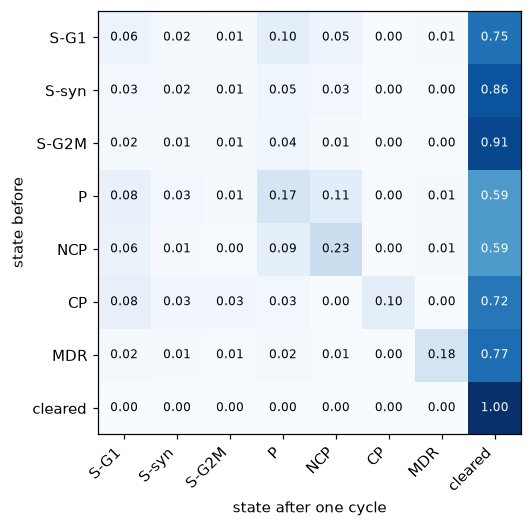

In [34]:
#transition matrix for Osi-Doce
show_matrix(pd.DataFrame(P_osi_doc, index=OUTCOMES, columns = OUTCOMES))

In [35]:
pd.DataFrame(evolve(pi_mix, P_osi_doc, 4), columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.050,0.019,0.012,0.076,0.058,0.010,0.033,0.741
2,0.015,0.005,0.003,0.026,0.025,0.001,0.008,0.918
3,0.005,0.002,0.001,0.009,0.009,0.000,0.002,0.973
4,0.002,0.001,0.000,0.003,0.003,0.000,0.001,0.991


In [36]:
# Checking with basis initial vector
pd.DataFrame(evolve(basis("S-G1", P_hat), P_osi_doc, 4), columns=OUTCOMES).round(3) 

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000
1,0.060,0.023,0.011,0.101,0.050,0.0,0.008,0.747
2,0.016,0.005,0.003,0.030,0.026,0.0,0.004,0.917
3,0.005,0.002,0.001,0.009,0.010,0.0,0.002,0.971
4,0.002,0.001,0.000,0.003,0.004,0.0,0.001,0.990


In [37]:
P_doc_osi = P_doc @ P_osi

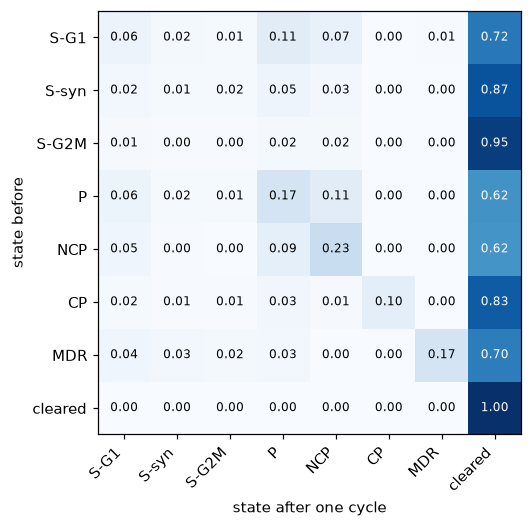

In [38]:
# Transition matrix for Doce-Osi
show_matrix(pd.DataFrame(P_doc_osi, index=OUTCOMES, columns = OUTCOMES))

In [39]:
pd.DataFrame(evolve(pi_mix, P_doc_osi, 4), columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.041,0.014,0.012,0.081,0.066,0.010,0.029,0.747
2,0.012,0.003,0.003,0.027,0.028,0.001,0.006,0.920
3,0.004,0.001,0.001,0.009,0.011,0.000,0.001,0.973
4,0.001,0.000,0.000,0.003,0.004,0.000,0.000,0.991


In [40]:
# Checking with basis initial vector
pd.DataFrame(evolve(basis("S-G1", P_hat), P_doc_osi, 4), columns=OUTCOMES).round(3) 

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000
1,0.058,0.016,0.012,0.111,0.075,0.0,0.006,0.722
2,0.014,0.003,0.003,0.034,0.035,0.0,0.002,0.909
3,0.005,0.001,0.001,0.011,0.013,0.0,0.001,0.969
4,0.002,0.000,0.000,0.004,0.005,0.0,0.000,0.989


<div class='alert alert-success'>
<b>Answer:</b> 

- After 4 rounds of alternating treatments, Osi-Doc and Doc-Osi both eliminate 99% of the cells.
- The transition matrices obtained from mulitplication of OSI-DOC and DOC-OSI are different mathematically because, as per matrix multiplication AB is not equal to BA.
- But in this situation, as we are doing multiple cycles of treatment, after 4 cycles both matrices give similar results with 99.1% cells eliminated.
- Even if the tumor is changed, the results are almost similar for both as the transition matrices are quite similar, and we do it for 4 cycles.
- Drug Holiday would help if the alternating schedules matrix had an absorbing state, because drug holiday matrix does not have any absorbing state and alternating other treatments with holiday would help removing cells from those absorbing state.
</div>

### Simultion with different pi and different transition matrix

In [41]:
P_osi_holiday = P_osi @ P_holiday
P_doc_holiday = P_doc @ P_holiday

# We have six transition matrices to check - P_oci, P_doc, P_oci_doc, P_doc_oci, P_osi_holiday, P_doc_holiday


Starting in state S-G1: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
Osi          0.001  0.000  0.000  0.003  0.005  0.0  0.000    0.989
Doc          0.002  0.001  0.000  0.003  0.003  0.0  0.063    0.927
Osi→Doc      0.002  0.001  0.000  0.003  0.004  0.0  0.001    0.990
Doc→Osi      0.002  0.000  0.000  0.004  0.005  0.0  0.000    0.989
Osi→Holiday  0.011  0.005  0.003  0.006  0.005  0.0  0.000    0.970
Doc→Holiday  0.023  0.014  0.009  0.007  0.006  0.0  0.007    0.934

Starting in state S-G1 with different treatments


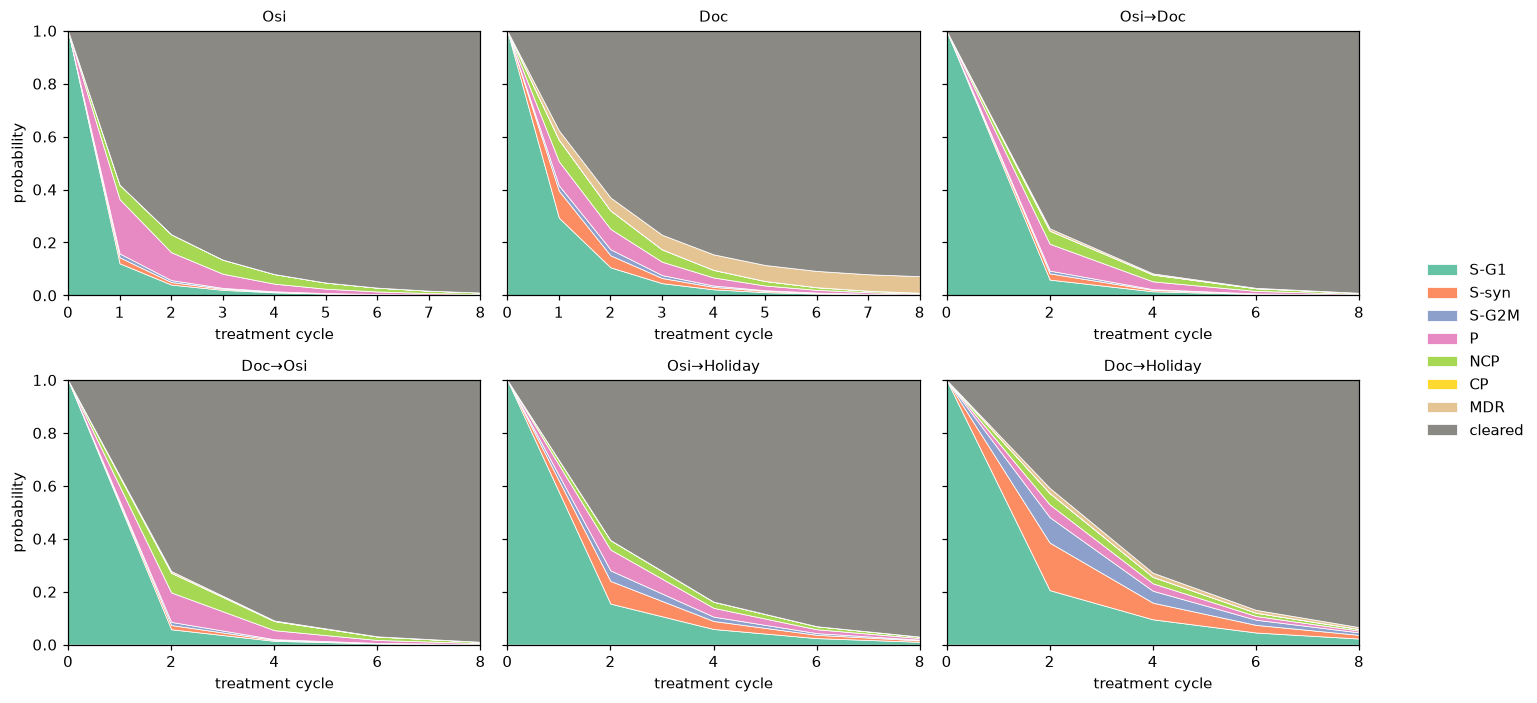


Starting in state S-syn: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
Osi          0.001  0.000  0.000  0.002  0.003  0.0  0.000    0.994
Doc          0.001  0.000  0.000  0.001  0.001  0.0  0.008    0.988
Osi→Doc      0.001  0.000  0.000  0.002  0.002  0.0  0.000    0.995
Doc→Osi      0.001  0.000  0.000  0.002  0.002  0.0  0.000    0.995
Osi→Holiday  0.006  0.003  0.002  0.004  0.003  0.0  0.000    0.982
Doc→Holiday  0.011  0.007  0.005  0.004  0.003  0.0  0.002    0.967

Starting in state S-syn with different treatments


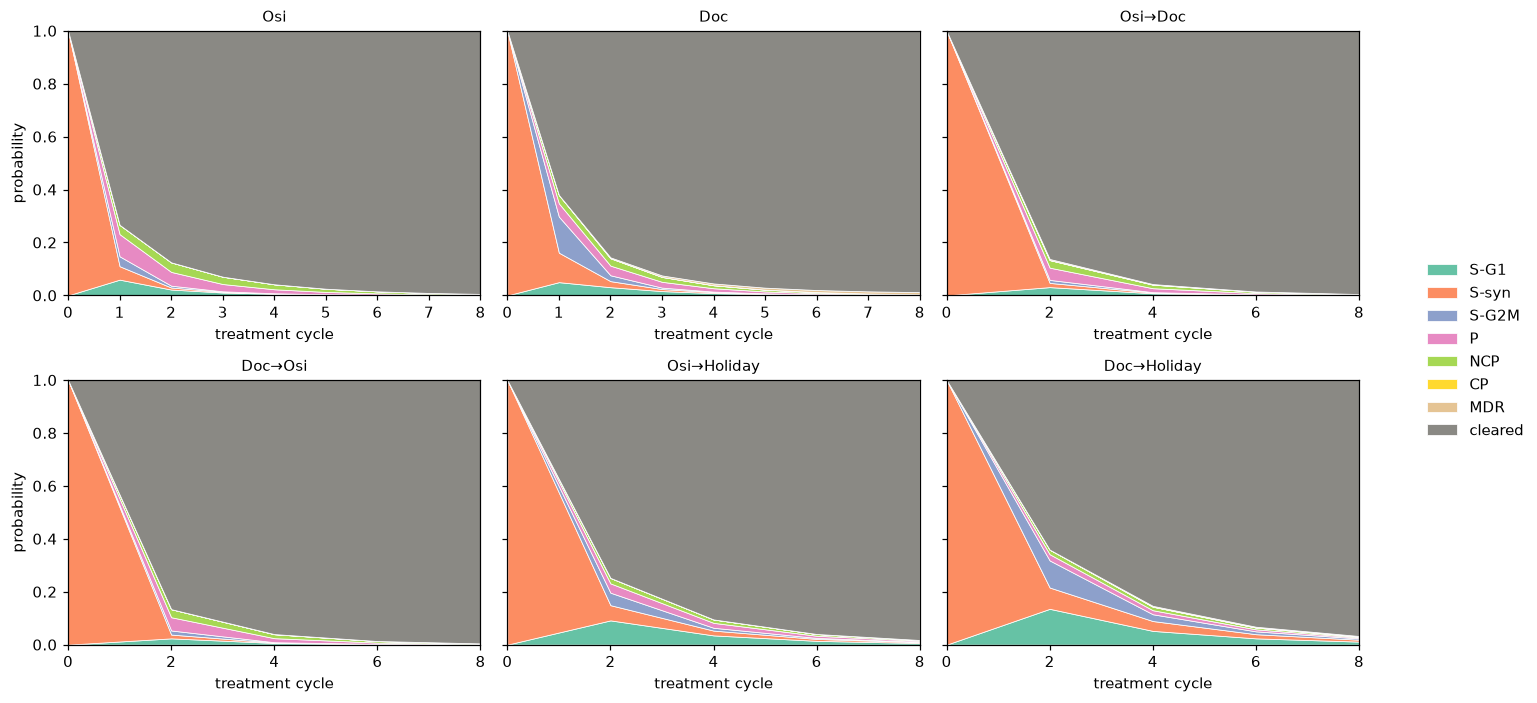


Starting in state S-G2M: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
Osi          0.000  0.000  0.000  0.001  0.002  0.0  0.000    0.996
Doc          0.000  0.000  0.000  0.001  0.001  0.0  0.004    0.994
Osi→Doc      0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.997
Doc→Osi      0.000  0.000  0.000  0.001  0.001  0.0  0.000    0.998
Osi→Holiday  0.004  0.002  0.001  0.003  0.002  0.0  0.000    0.987
Doc→Holiday  0.004  0.003  0.002  0.001  0.001  0.0  0.001    0.988

Starting in state S-G2M with different treatments


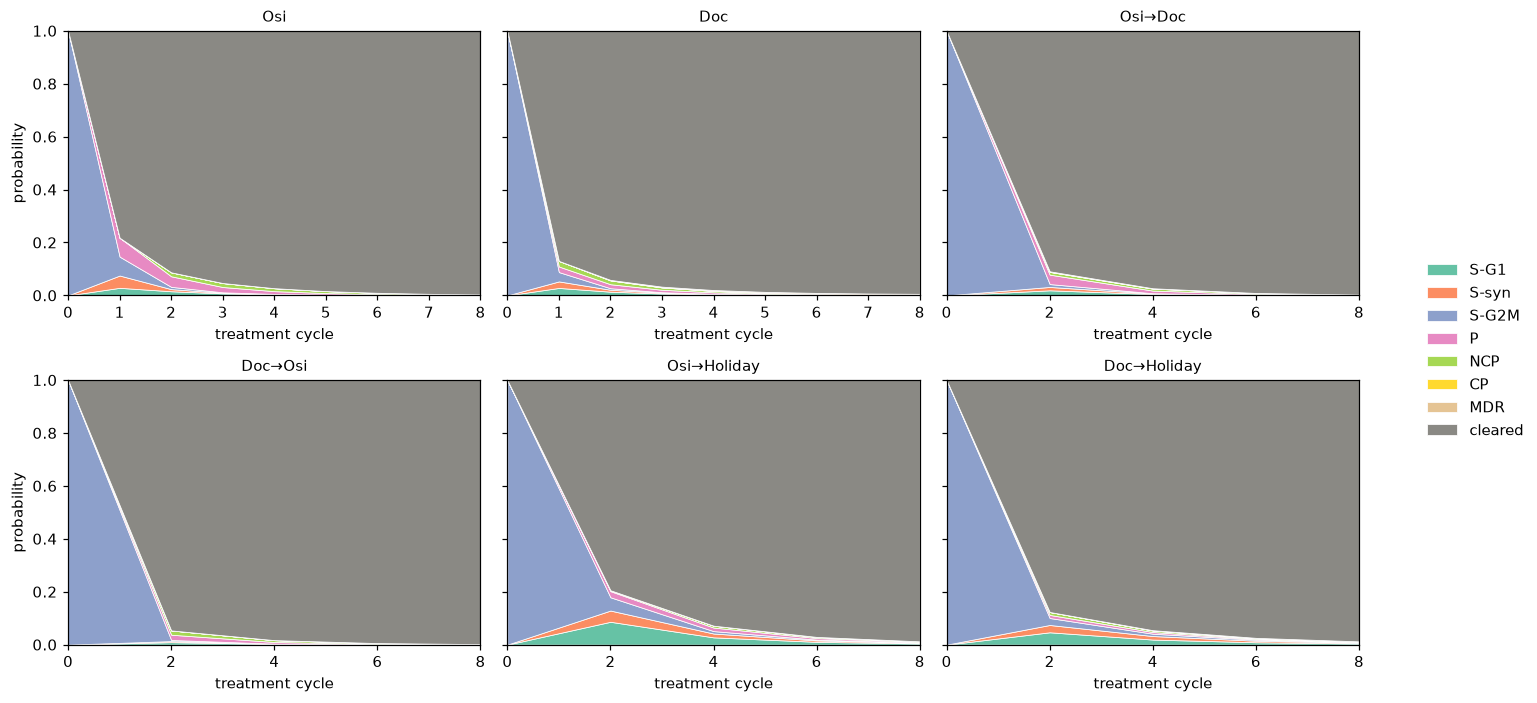


Starting in state P: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
Osi          0.003  0.000  0.000  0.006  0.010  0.0  0.000    0.981
Doc          0.003  0.001  0.001  0.004  0.004  0.0  0.041    0.945
Osi→Doc      0.003  0.001  0.000  0.005  0.006  0.0  0.001    0.983
Doc→Osi      0.002  0.000  0.000  0.005  0.007  0.0  0.000    0.985
Osi→Holiday  0.019  0.010  0.005  0.011  0.010  0.0  0.000    0.946
Doc→Holiday  0.027  0.017  0.011  0.008  0.008  0.0  0.006    0.923

Starting in state P with different treatments


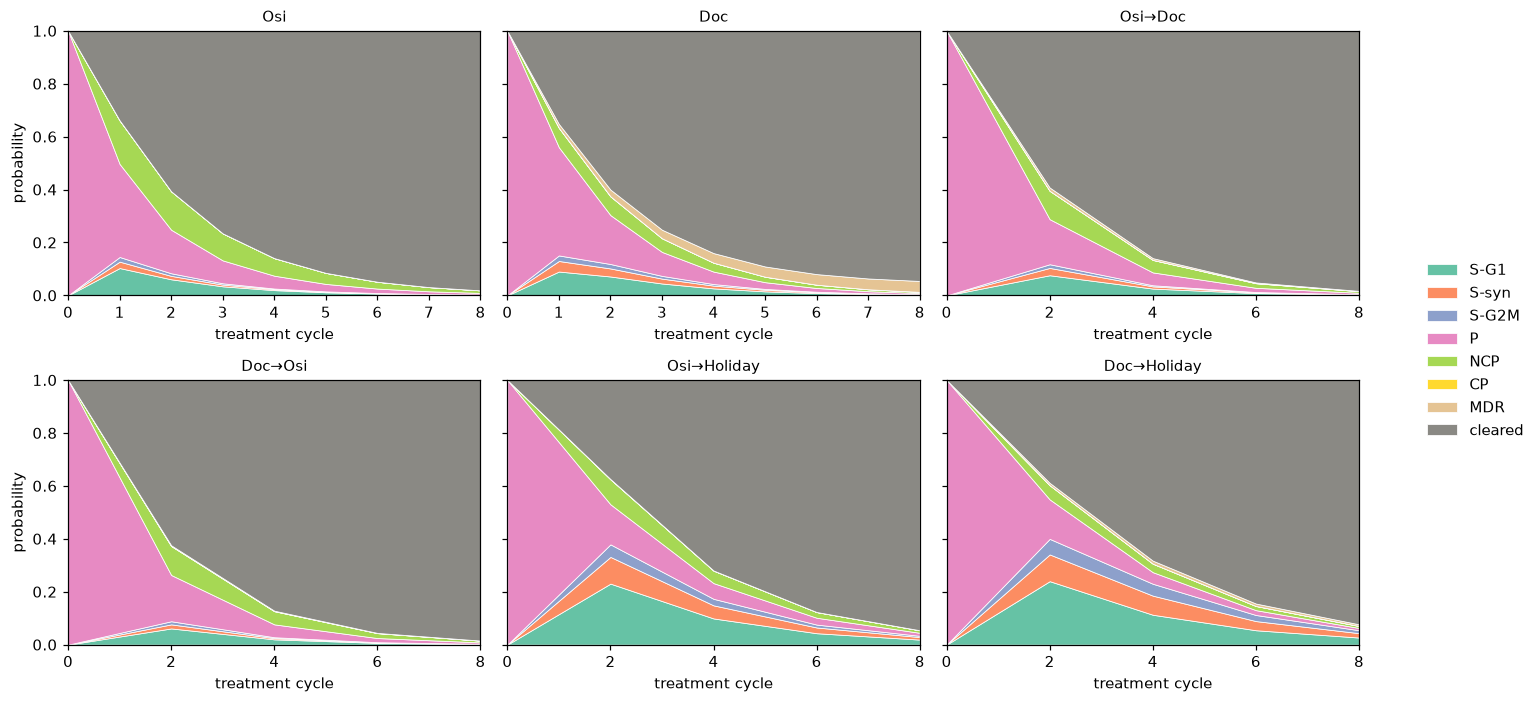


Starting in state NCP: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
Osi          0.003  0.000  0.000  0.007  0.011  0.0  0.000    0.978
Doc          0.003  0.001  0.001  0.005  0.005  0.0  0.054    0.932
Osi→Doc      0.003  0.001  0.000  0.006  0.007  0.0  0.001    0.981
Doc→Osi      0.003  0.001  0.000  0.006  0.008  0.0  0.000    0.983
Osi→Holiday  0.023  0.012  0.006  0.014  0.013  0.0  0.000    0.932
Doc→Holiday  0.031  0.019  0.012  0.010  0.009  0.0  0.007    0.910

Starting in state NCP with different treatments


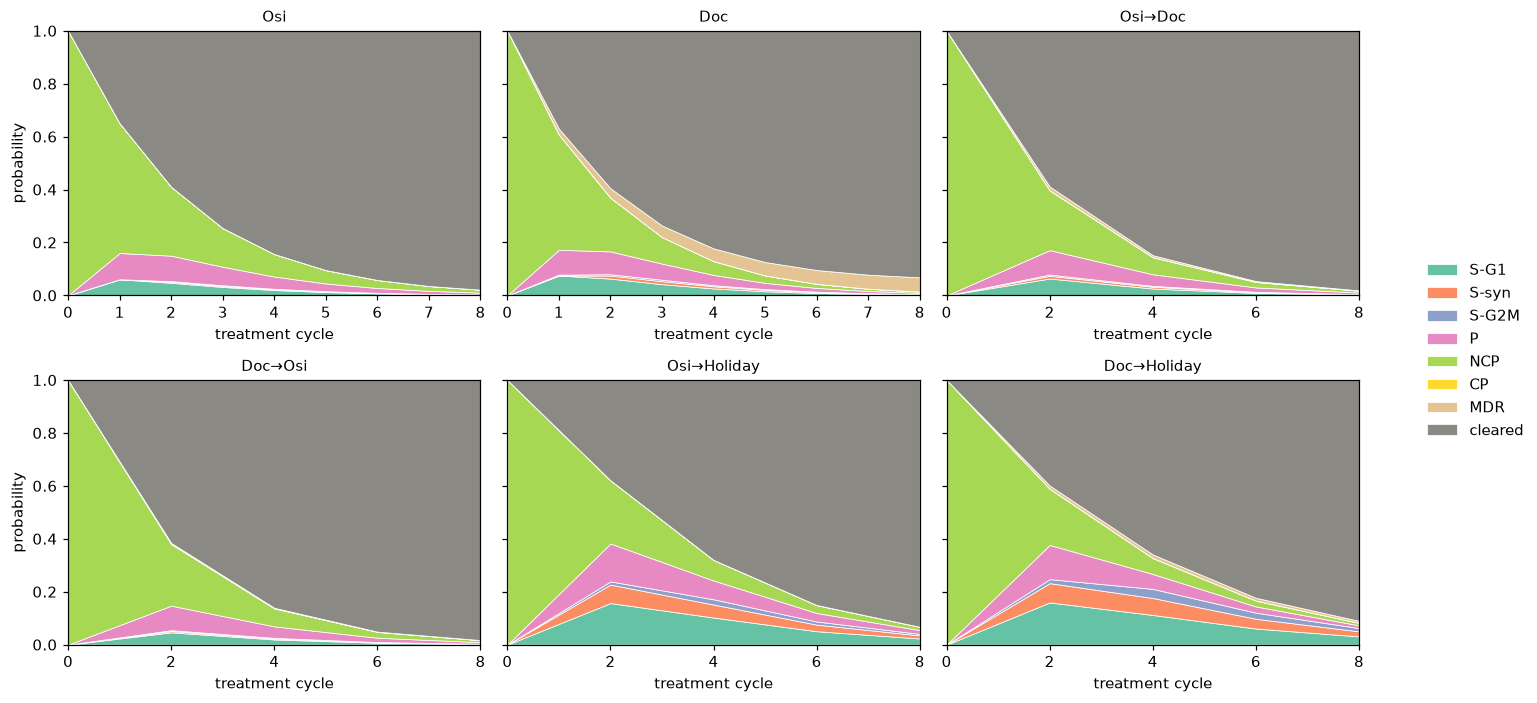


Starting in state CP: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
Osi          0.000  0.000  0.000  0.000  0.000  1.000  0.000    0.000
Doc          0.001  0.000  0.000  0.001  0.001  0.000  0.007    0.990
Osi→Doc      0.001  0.000  0.000  0.002  0.002  0.000  0.000    0.994
Doc→Osi      0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996
Osi→Holiday  0.050  0.027  0.026  0.008  0.005  0.453  0.000    0.432
Doc→Holiday  0.007  0.004  0.003  0.002  0.002  0.000  0.001    0.981

Starting in state CP with different treatments


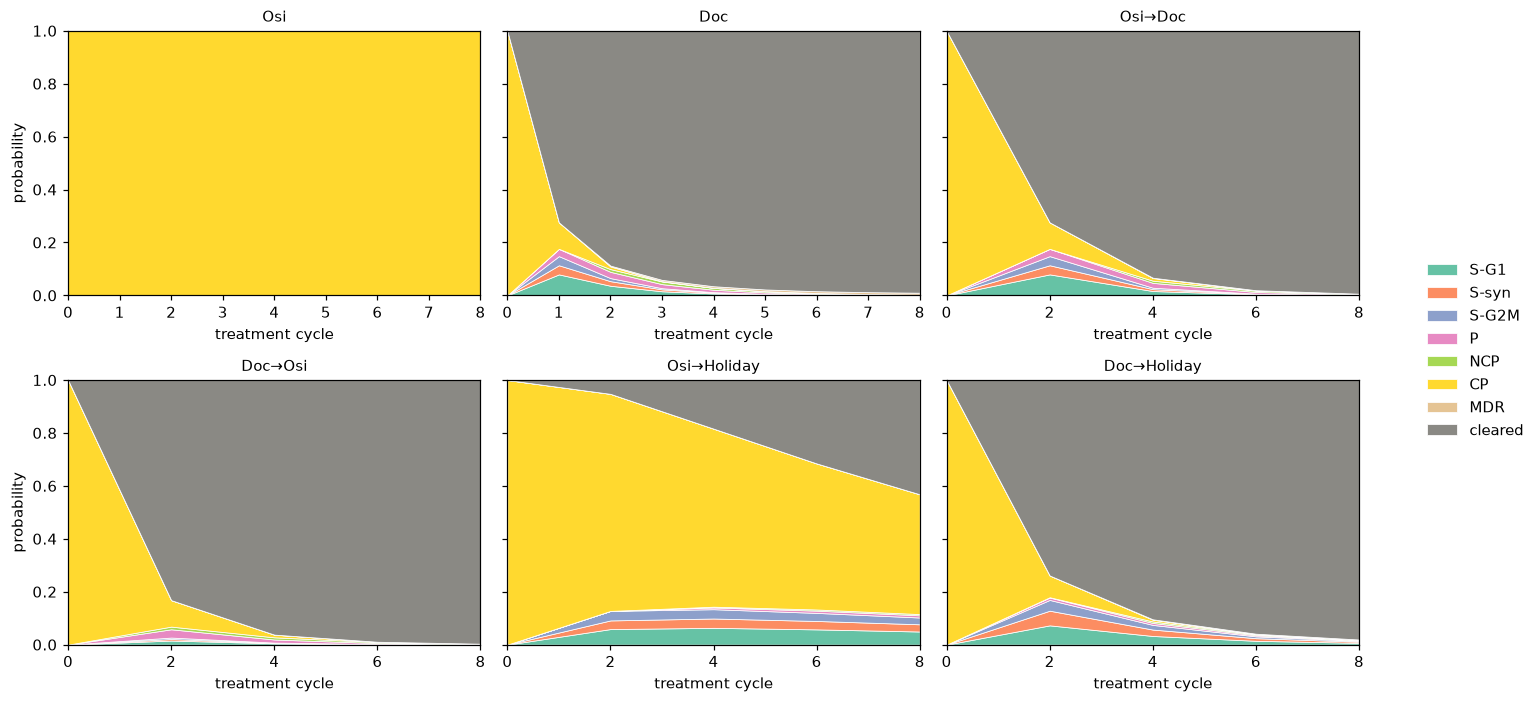


Starting in state MDR: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
Osi          0.000  0.000  0.000  0.001  0.001  0.0  0.000    0.997
Doc          0.000  0.000  0.000  0.000  0.000  0.0  1.000    0.000
Osi→Doc      0.001  0.000  0.000  0.001  0.001  0.0  0.001    0.995
Doc→Osi      0.001  0.000  0.000  0.002  0.002  0.0  0.001    0.993
Osi→Holiday  0.005  0.003  0.001  0.003  0.002  0.0  0.000    0.986
Doc→Holiday  0.107  0.047  0.033  0.015  0.014  0.0  0.094    0.689

Starting in state MDR with different treatments


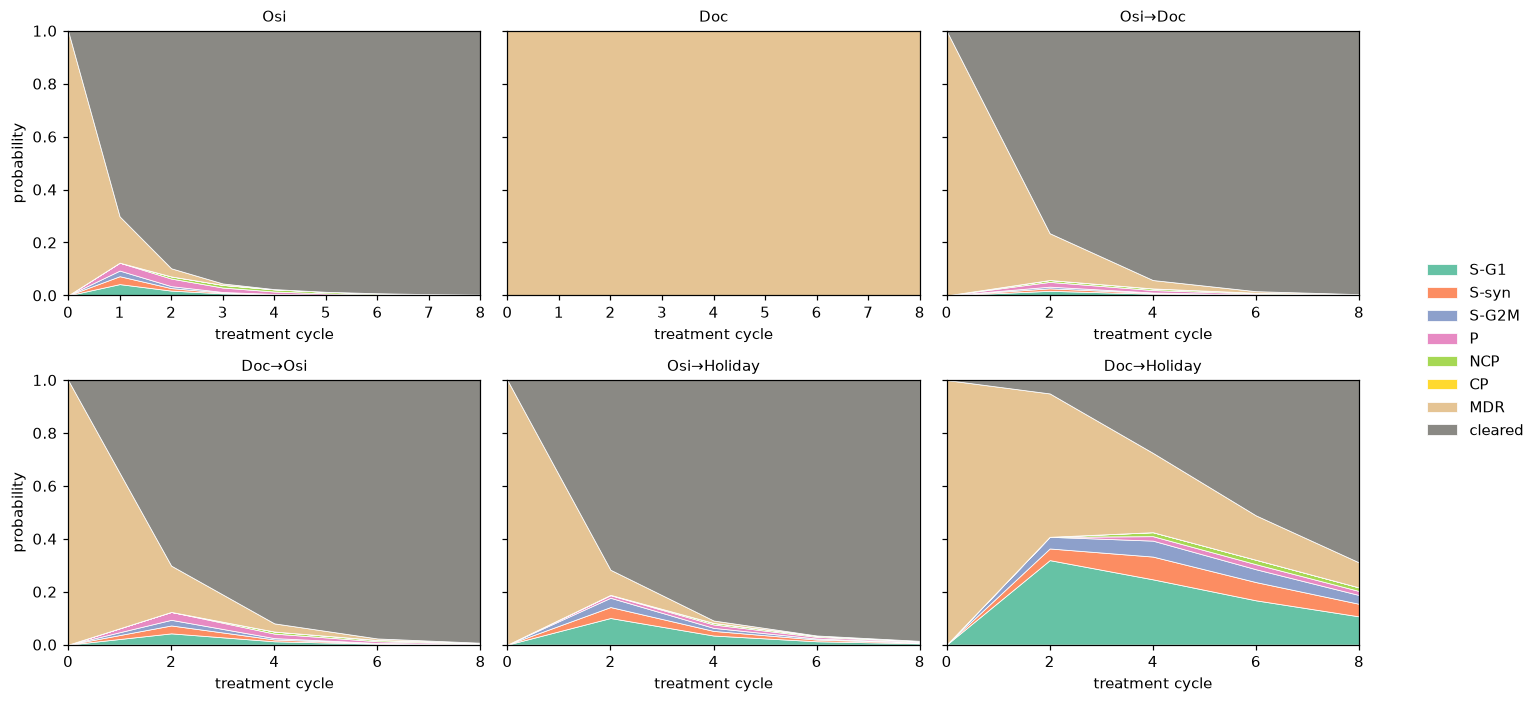


Starting in state pi mix: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
Osi          0.001  0.000  0.000  0.003  0.005  0.097  0.000    0.893
Doc          0.002  0.001  0.000  0.002  0.002  0.000  0.183    0.810
Osi→Doc      0.002  0.001  0.000  0.003  0.003  0.000  0.001    0.991
Doc→Osi      0.001  0.000  0.000  0.003  0.004  0.000  0.000    0.991
Osi→Holiday  0.015  0.008  0.005  0.007  0.005  0.044  0.000    0.916
Doc→Holiday  0.032  0.017  0.012  0.007  0.006  0.000  0.018    0.907

Starting in state pi mix with different treatments


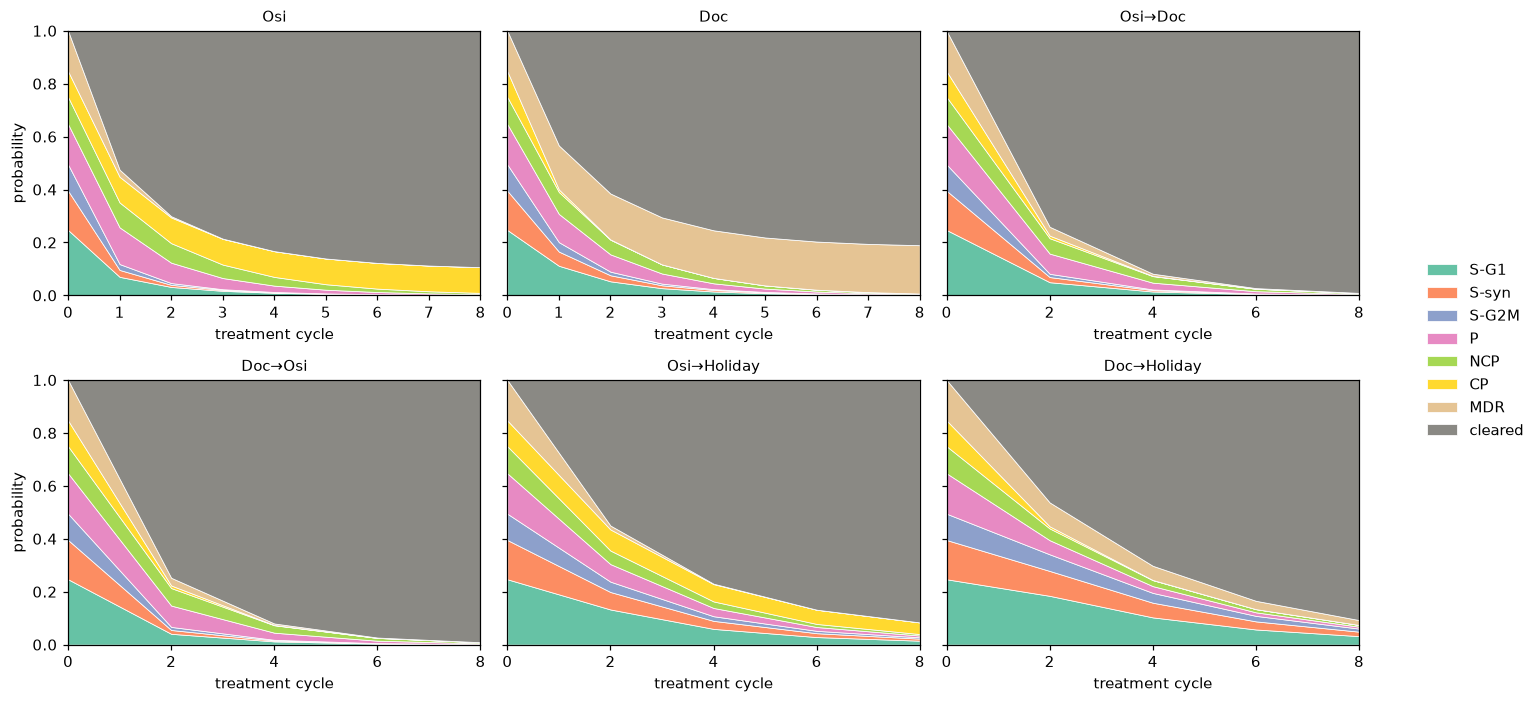


Starting in state equal mix: final state after 8 cycles with different treatments
              S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
Osi          0.001  0.000  0.000  0.003  0.005  0.143  0.000    0.848
Doc          0.001  0.001  0.000  0.002  0.002  0.000  0.168    0.825
Osi→Doc      0.002  0.001  0.000  0.003  0.003  0.000  0.001    0.991
Doc→Osi      0.001  0.000  0.000  0.003  0.004  0.000  0.000    0.991
Osi→Holiday  0.017  0.009  0.006  0.007  0.006  0.065  0.000    0.891
Doc→Holiday  0.030  0.016  0.011  0.007  0.006  0.000  0.017    0.913

Starting in state equal mix with different treatments


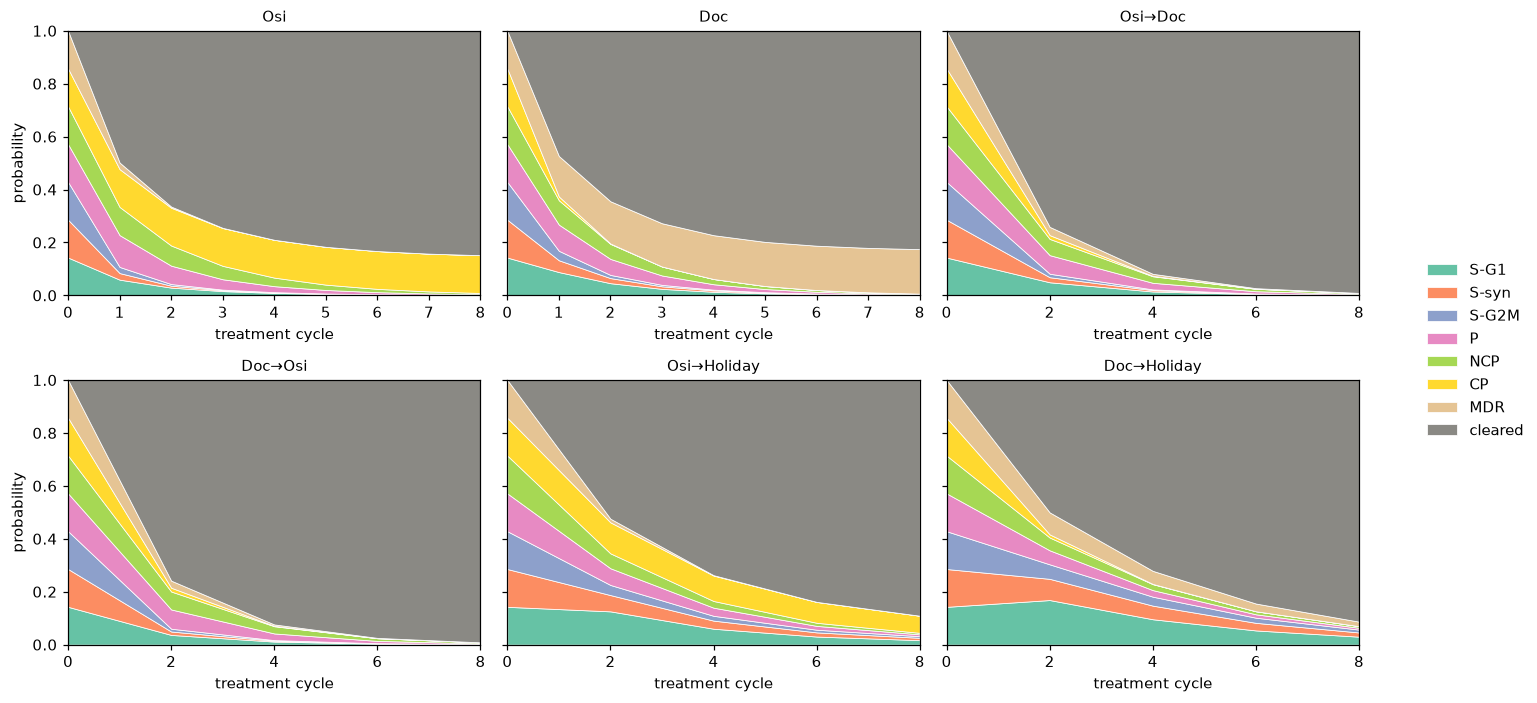

In [42]:
# schedule name -> (transition matrix, cycles per step)
schedules = {
    "Osi":         (P_osi, 1),
    "Doc":         (P_doc, 1),
    "Osi→Doc":     (P_osi_doc, 2),
    "Doc→Osi":     (P_doc_osi, 2),
    "Osi→Holiday": (P_osi_holiday, 2),
    "Doc→Holiday": (P_doc_holiday, 2),
}
N_TOTAL = 8   # total cycles for every schedule

starts = {s: basis(s, P_hat) for s in STATES}
starts["pi mix"] = pi_mix
starts["equal mix"] = np.append(np.ones(len(STATES)) / len(STATES), 0)   # 1/7 each, 0 for cleared

for s, pi0 in starts.items():
    trajs = {name: evolve(pi0, P, N_TOTAL // cps) for name, (P, cps) in schedules.items()}

    print(f"\nStarting in state {s}: final state after {N_TOTAL} cycles with different treatments")
    final_df = pd.DataFrame({name: traj[-1] for name, traj in trajs.items()},
                            index=OUTCOMES).T
    print(final_df.round(3))

    print(f"\nStarting in state {s} with different treatments")
    fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharey=True)
    for ax, (name, traj) in zip(axes.flat, trajs.items()):
        cps = schedules[name][1]
        plot_trajectory(traj, ax, name)
        ticks = np.arange(len(traj))
        ax.set_xticks(ticks, ticks * cps)   # x-axis shows cycles, not paired steps
    for ax in axes[:, 0]:
        ax.set_ylabel("probability")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right", frameon=False)
    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.show()

In [43]:
def rounds_to_clear(pi0, P, cps, max_cycles=20, tol=0.01):
    traj = evolve(pi0, P, max_cycles // cps)
    alive = 1 - traj[:, -1]
    hit = np.where(alive < tol)[0]
    return hit[0] * cps if len(hit) else np.nan   # nan = never reaches the threshold

rounds_table = pd.DataFrame(
    {name: [rounds_to_clear(pi0, P, cps) for pi0 in starts.values()]
     for name, (P, cps) in schedules.items()},
    index=list(starts))

rounds_table

,Osi,Doc,Osi→Doc,Doc→Osi,Osi→Holiday,Doc→Holiday
S-G1,9.0,NaN,8,10,12.0,14.0
S-syn,7.0,10.0,8,8,10.0,12.0
S-G2M,6.0,6.0,6,6,10.0,10.0
P,10.0,NaN,10,10,14.0,16.0
NCP,10.0,NaN,10,10,14.0,16.0
CP,NaN,9.0,8,8,NaN,10.0
MDR,6.0,NaN,8,8,10.0,NaN
pi mix,NaN,NaN,8,8,NaN,16.0
equal mix,NaN,NaN,8,8,NaN,16.0


<div class='alert alert-success'>
<b>Answer:</b>

**Treatment prescription** (based on rounds table)
| Tumor composition | Prescription | Min Cycles |
|---|---|---|
| Entirely S-G1 | Osi-Doc cycle preferred, but Doc-Osi also works | 8 (Osi-Doc)|
| Entirely S-syn | osimertinib | 7 |
| Entirely S-G2M | osimertinib | 6 |
| Entirely P or NCP | osimertinib or alternate | 10 |
| Entirely CP | either alternating cycle | 8 |
| Entirely MDR | osimertinib | 6 |
| Some mix (here pi_mix) | either alternating cycle | 8 |
| Equal mix (equal initial proportion) | either alternating cycle | 8 |

- Never give a single drug to a tumor that contains that drug's absorbing state (CP for osimertinib, MDR for docetaxel), because it will never be cleared.
</div>

## 6. Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [44]:
rng = np.random.default_rng(100)

In [45]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [46]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

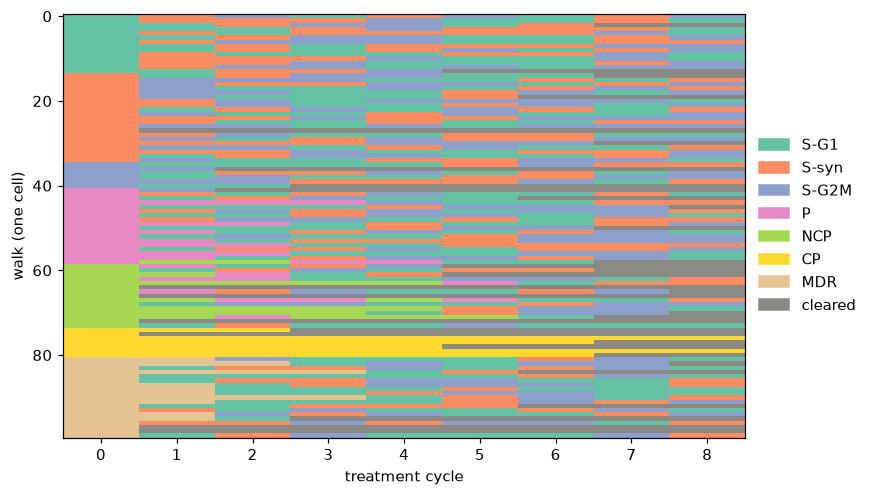

In [47]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [48]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

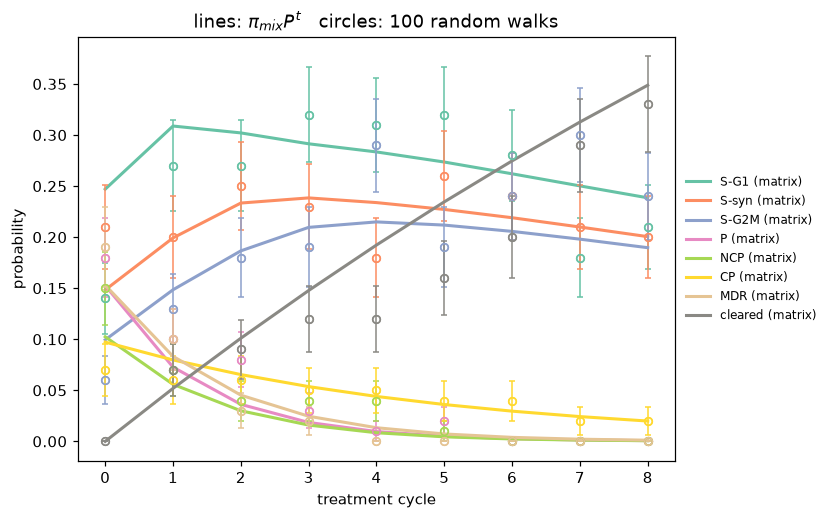

In [49]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

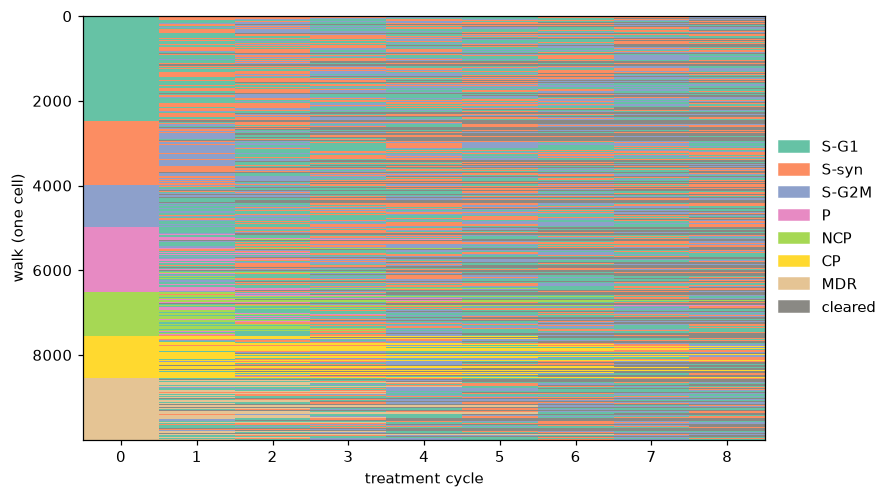

In [50]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [51]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

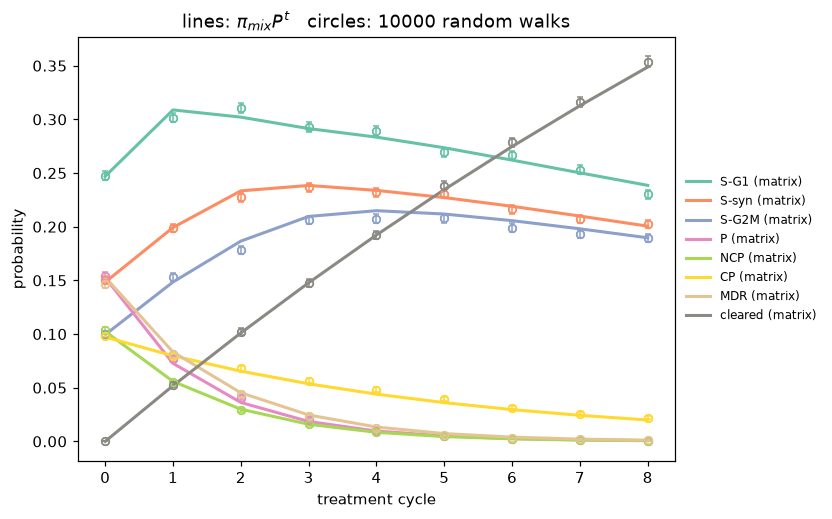

In [52]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

<div class = 'alert alert-success'><b>Answer:</b>

- the lines show the exact proportion from the evolve function. circles show the estimated proportion from 100/10000 walks.
- For 100 walks, the points/circles sit away from the lines, with big standard deviations. 
- For 10000 walks, as we know as the sample size increase the estimated mean gets closer to actual value and standard deviation gets smaller, as it is inversely proportional to n. (Law of large numbers)
- Hence, for 10000 walks the circles are almost on the line.
</div>

## 7. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [53]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

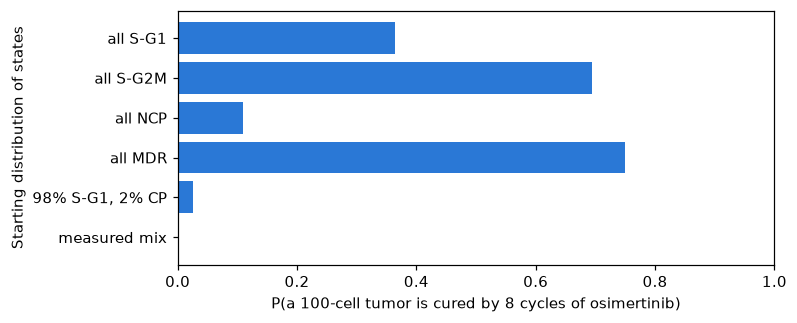

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [54]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

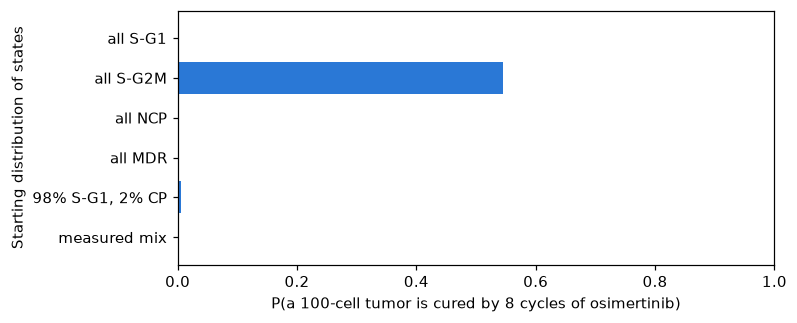

,P(cured),mean surviving cells,share of survivors that are MDR
start,,,
all S-G1,0.000,7.805,0.863
all S-G2M,0.545,0.610,0.631
all NCP,0.000,6.690,0.800
all MDR,0.000,100.000,1.000
"98% S-G1, 2% CP",0.005,6.985,0.866
measured mix,0.000,18.955,0.964


In [55]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

<div class="alert alert-success"> 

- While running with docetaxel, changed the last column to survivors in MDR, as MDR is an absorbing state for docetaxel
- On running the simulation with docetaxel, we get very poor cured results.
- As learnt from the docetaxel transition matrix, the states S-G1, P, and NCP transition into MDR, but cannot transition further after reaching there.
- Hence for all SG1, all NCP and all MDR (all in absorbing state), there are zero survivors as most of them end up in MDR.
- Only S-G2M has a good curing rate as its clearing rate with docetaxel is very high.
- Compared to osimertinib, osimertinib cannot kill anything in CP, but kills MDR. Inversely docetaxel cannot kill anything in MDR, but can kill CP.
- For osimertinib, the results are better because no state can transit into CP, hence a cell reaches CP only if there were cells of CP initially.
</div>

## 8. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [57]:
# code written with help from Claude AI
persister = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def walk_schedule(start, schedule, rng):
    path = [start]
    for P_k in schedule: #schedule added as matrix needs to change for alternating treatments
        path.append(step(path[-1], P_k, rng))
    return path #returns path of cell for 8 transitions

def longest_persister_run(path):
    best = run = 0
    for s in path:
        run = run + 1 if s in persister else 0
        best = max(best, run)
    return best #returns length for longest stay in P or NCP 

def pr_proportion_one_tumor(pi0, schedule, n_cells, rng):
    starts = rng.choice(len(pi0), size=n_cells, p=pi0) #generates 1000 starting states
    #for each start, do a random walk, calculate length for p/ncp state, add if length is more than 3 and calculate mean
    return np.mean([longest_persister_run(walk_schedule(int(s0), schedule, rng)) >= 3 for s0 in starts]) 

def pr_summary(schedule, n_tumors, n_cells):
    fr = np.array([pr_proportion_one_tumor(pi_mix, schedule, n_cells, rng) for _ in range(n_tumors)])
    mean, sem = fr.mean(), fr.std(ddof=1) / np.sqrt(n_tumors)
    return {'mean' : mean, 'SEM' : sem,
            'CI low' : mean - 1.96 * sem, 'CI high' : mean + 1.96 * sem,
            '% tumors > 10% PR': 100 * np.mean(fr > 0.10)}


N_CELLS, N_TUMORS = 1000, 100

osi_pr = pr_summary([P_osi] * 8, N_TUMORS, N_CELLS)
print('Osimertinib, 8 cycles')
print(f'Mean for proportion of persister {round(osi_pr['mean'],3)} +/- {round(osi_pr['SEM'],3)}')
print(f'95% confidence interal : [{round(osi_pr['CI low'],3)},{round(osi_pr['CI high'],3)}]')

Osimertinib, 8 cycles
Mean for proportion of persister 0.116 +/- 0.001
95% confidence interal : [0.114,0.118]


**Confidence interval [0.114,0.118] does not contain 0.10, hence we reject the hypothesis that the proportion is 10%**

In [58]:
# Compare treatments and numbers of cycles
pattern = {"Osimertinib alone": [P_osi],
               "Docetaxel alone": [P_doc],
               "Alternating OD": [P_osi, P_doc],
               "Docetaxel + holiday": [P_doc, P_holiday]}

def make_schedule(name, n_cycles):
    matrix = pattern[name]
    return [matrix[k % len(matrix)] for k in range(n_cycles)] #len(matrix) added to accomodate alternating matrices

rows = []
for name in ["Osimertinib alone", "Docetaxel alone", "Alternating OD", "Docetaxel + holiday"]:
    for n_cycles in [8, 12, 16]:
        rows.append({"treatment": name, "cycles": n_cycles, **pr_summary(make_schedule(name, n_cycles), N_TUMORS, N_CELLS)})
pr_table = pd.DataFrame(rows).set_index(["treatment", "cycles"])
pr_table.round(4)

mean     SEM  CI low  CI high  % tumors > 10% PR
treatment           cycles                                                    
Osimertinib alone   8       0.1146  0.0011  0.1125   0.1167               90.0
                    12      0.1146  0.0011  0.1125   0.1167               90.0
                    16      0.1165  0.0011  0.1144   0.1186               93.0
Docetaxel alone     8       0.0913  0.0010  0.0893   0.0933               21.0
                    12      0.0929  0.0009  0.0911   0.0947               21.0
                    16      0.0939  0.0009  0.0923   0.0956               24.0
Alternating OD      8       0.1070  0.0010  0.1051   0.1089               79.0
                    12      0.1064  0.0012  0.1041   0.1087               67.0
                    16      0.1059  0.0010  0.1039   0.1079               72.0
Docetaxel + holiday 8       0.0988  0.0010  0.0969   0.1007               40.0
                    12      0.1023  0.0008  0.1007   0.1040               55.0
                    16      0.1036  0.0010  0.1017   0.1055               62.0

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

<div class='alert alert-success'>
<b>Answer:</b>

| Treatment | % tumors > 10% PR (8 / 12 / 16 cycles) | mean PR fraction at 8 cycles (95% CI) |
|---|---|---|
| Osimertinib alone | 90% / 90% / 93% | 11.5% |
| Docetaxel alone | 21% / 21% / 24% | 9.1%|
| Alternating OD | 79% / 67% / 72% | 10.7% |
| Docetaxel + holiday | 40% / 55% / 62% | 9.9% |

- Overall, Osimertinib performs the worst. Its 95% CI is entirely above 10%, so it significantly exceeds the threshold. Osimertinib transition matrix has high P-P and NCP-NCP probability, hence cells reached there have a high probability of not transiting and becoming resistant.
- Docetaxel alone performs the best, and has the lowest mean. However, it creates MDR cells instead.
- Alternating OD is slightly above 10%.
- For Docetaxel + holiday, the holiday lets persisters relax back into sensitive states. With more cycles it creeps up to about 10%.
- Effect of more cycles: the PR fraction rises with the number of cycles for every treatment, because each extra cycle is another chance for a persister to reach 3 in a row.
</div>